In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from utilities import get_extracted_files, read_nccsv
from utilities import detect_threshold_blooms, run_phytobloom_pipeline, plot_seasonal_bloom_trends

In [ ]:
# Load directly from your pipeline output (or use res['events_df'] in memory)
_, events_df = read_nccsv(res['output_files']['events'])

# 1. Single region & season plot
plot_seasonal_bloom_trends(
    events_df, subarea='Georges Bank', season='Fall', year_range=(1998, 2025)
)

# 2. All regions & seasons + summary table of significant trends
trends_df = run_bloom_trend_analysis(
    events_df,
    seasons=('Spring', 'Fall'),
    year_range=(1998, 2025),
    output_dir='/path/to/figures/phytoblooms',
    show=True
)

# Filter to statistically significant changes (p < 0.05)
display(trends_df[trends_df['Significant']][
    ['subarea', 'Season', 'Metric', 'Slope_Per_Decade', 'R_Squared', 'P_Value']
])

In [19]:
results = run_phytobloom_pipeline(
    regions='NES_5REGIONS',
    datasets='OCCCI',
    periods='D7',
    year_range=(1998, 2025),
    overwrite=True,
    verbose=True
)

# Inspect outputs directly in memory
res = results[('OCCCI', 'NES_5REGIONS', 'D7')]
display(res['events_df'].head())
display(res['annual_df'].head())


🚀 Processing Phytoblooms: OCCCI | NES_5REGIONS | D7
  ✅ Saved: D7-OCCCI-PHYTOBLOOMS-METRICS-NES_5REGIONS-EXTRACTED_DATA.csv
  ✅ Saved: D7-OCCCI-PHYTOBLOOMS-EVENTS-NES_5REGIONS-EXTRACTED_DATA.csv (21 events)
  ✅ Saved: D7-OCCCI-PHYTOBLOOMS-ANNUAL-NES_5REGIONS-EXTRACTED_DATA.csv (140 rows)

🏁 PHYTOBLOOM PIPELINE SUMMARY
✅ Processed: 1
⏭️ Skipped:   0
❌ Failed:    0


,subarea,Bloom_ID,Year,Biological_Year,Season,Start_Date,Peak_Date,End_Date,Start_DOY,Peak_DOY,...,First_Exceed_Date,Last_Drop_Date,Duration_Days,Duration_Above_Thld,Num_Peaks,Max_CHL,Max_ROC,Max_ROC_Date,Integrated_CHL,Integrated_CHL_Above_Thld
0,Georges Bank,1,2006,2006,Fall,1997-12-30,2006-11-13,2006-12-09,364,317,...,2006-11-04,2006-12-05,43,31,1,1.421243,0.120580,2006-11-25,3052.815600,30.942471
1,Georges Bank,2,2007,2006,Spring,2007-03-09,2007-03-30,2007-04-26,68,89,...,2007-03-18,2007-04-13,48,26,1,1.968480,0.095340,2007-03-22,62.046450,40.752686
2,Georges Bank,3,2007,2007,Summer,2007-07-26,2007-08-17,2007-08-24,207,229,...,2007-08-02,2007-08-21,29,19,1,1.310193,0.062118,2007-08-01,33.331475,23.325045
3,Georges Bank,4,2007,2007,Fall,2007-08-26,2007-10-18,2007-11-18,238,291,...,2007-09-09,2007-11-03,84,55,3,1.699597,0.088952,2007-10-14,105.581221,76.984695
4,Gulf of Maine East,1,2007,2006,Spring,2007-03-04,2007-04-08,2007-04-29,63,98,...,2007-03-25,2007-04-17,56,23,1,2.531800,0.223293,2007-04-05,62.839128,40.949475


,subarea,Year,Num_Blooms_Cal,Num_Spring_Blooms,Num_Fall_Blooms,Bloom_Days_Cal,Bloom_Days_Above_Thld_Cal,Pct_Bloom_Days_Above_Thld_Cal,Total_Integrated_CHL_Cal,Bloom_Integrated_CHL_Cal,Pct_CHL_In_Blooms_Cal,Num_Blooms_Bio,Bloom_Days_Bio,Bloom_Days_Above_Thld_Bio,Pct_Bloom_Days_Above_Thld_Bio,Total_Integrated_CHL_Bio,Bloom_Integrated_CHL_Bio,Pct_CHL_In_Blooms_Bio
0,Georges Bank,1998,0,0,0,3,0,0.0,1.6,1.6,100.0,0,0,0,0.0,0.0,0.0,0.0
1,Georges Bank,1999,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0.0,0.0,0.0,0.0
2,Georges Bank,2000,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0.0,0.0,0.0,0.0
3,Georges Bank,2001,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0.0,0.0,0.0,0.0
4,Georges Bank,2002,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0.0,0.0,0.0,0.0


In [8]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd


def plot_bloom_diagnostics(df, events_df, clim_thld_lookup, subarea='GB', year=1999,
                           var_name='CHL_Median', thld_frac=0.10):
    """
    Plots a 2-panel diagnostic chart for a single subarea and year:
      - Top: Raw CHL, smoothed CHL, climatological median & threshold, shaded ROC
             bloom windows, initiation/termination markers, and peak CHL.
      - Bottom: Daily Rate of Change (ROC) with positive/negative shading and Max ROC.
    """
    smooth_col = f"{var_name}_smoothed"
    roc_col = f"{var_name}_ROC"

    clim_thld = clim_thld_lookup[subarea]
    clim_med = clim_thld / (1.0 + thld_frac)

    start_dt = pd.Timestamp(f"{year}-01-01")
    end_dt = pd.Timestamp(f"{year}-12-31")

    yr_df = df[(df['subarea'] == subarea) & (df['Date'] >= start_dt) & (df['Date'] <= end_dt)].sort_values('Date')

    ev_sub = events_df[events_df['subarea'] == subarea].copy()
    for col in ['Start_Date', 'Peak_Date', 'End_Date', 'Max_ROC_Date']:
        ev_sub[col] = pd.to_datetime(ev_sub[col])
    yr_events = ev_sub[(ev_sub['End_Date'] >= start_dt) & (ev_sub['Start_Date'] <= end_dt)]

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]}
    )

    # Top panel: CHL
    ax1.plot(yr_df['Date'], yr_df[var_name], color='lightgray', linewidth=1.2, label=f'Raw {var_name}', zorder=1)
    ax1.plot(yr_df['Date'], yr_df[smooth_col], color='royalblue', linewidth=2.0, label='Smoothed CHL', zorder=3)
    ax1.axhline(clim_thld, color='crimson', linestyle='--', linewidth=1.3, label=f'Threshold (+{int(thld_frac*100)}%): {clim_thld:.2f}')
    ax1.axhline(clim_med, color='dimgray', linestyle=':', linewidth=1.2, label=f'Annual Median: {clim_med:.2f}')

    # Bottom panel: ROC
    ax2.axhline(0, color='black', linewidth=0.9)
    ax2.plot(yr_df['Date'], yr_df[roc_col], color='teal', linewidth=1.5, label='Daily ROC (dCHL/dt)')
    ax2.fill_between(yr_df['Date'], 0, yr_df[roc_col], where=(yr_df[roc_col] >= 0), color='mediumseagreen', alpha=0.25)
    ax2.fill_between(yr_df['Date'], 0, yr_df[roc_col], where=(yr_df[roc_col] < 0), color='salmon', alpha=0.25)

    # Shade bloom windows & annotate key points
    for idx, (_, ev) in enumerate(yr_events.iterrows()):
        s_dt = max(ev['Start_Date'], start_dt)
        e_dt = min(ev['End_Date'], end_dt)
        ax1.axvspan(s_dt, e_dt, color='gold', alpha=0.22, label='ROC Bloom Window' if idx == 0 else None)
        ax2.axvspan(s_dt, e_dt, color='gold', alpha=0.22)

        s_val = yr_df.loc[yr_df['Date'] == ev['Start_Date'], smooth_col]
        e_val = yr_df.loc[yr_df['Date'] == ev['End_Date'], smooth_col]
        if not s_val.empty:
            ax1.scatter(ev['Start_Date'], s_val.values[0], color='green', marker='^', s=75, zorder=5,
                        label='Initiation (Start)' if idx == 0 else None)
        if not e_val.empty:
            ax1.scatter(ev['End_Date'], e_val.values[0], color='darkred', marker='v', s=75, zorder=5,
                        label='Termination (End)' if idx == 0 else None)
        if start_dt <= ev['Peak_Date'] <= end_dt:
            ax1.scatter(ev['Peak_Date'], ev['Max_CHL'], color='darkorange', marker='*', s=140, zorder=6,
                        label='Bloom Peak' if idx == 0 else None)
            ax1.annotate(f"ID {ev['Bloom_ID']}\n({ev['Max_CHL']:.2f})", (ev['Peak_Date'], ev['Max_CHL']),
                         textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9, fontweight='bold')
        if start_dt <= ev['Max_ROC_Date'] <= end_dt:
            ax2.scatter(ev['Max_ROC_Date'], ev['Max_ROC'], color='purple', marker='D', s=55, zorder=5,
                        label='Max ROC' if idx == 0 else None)

    ax1.set_title(f'Phytoplankton Bloom ROC Diagnostics — {subarea} ({year})', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Chlorophyll-a (mg m$^{-3}$)', fontsize=11)
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(loc='upper right', fontsize=9, ncol=2)

    ax2.set_ylabel('ROC (mg m$^{-3}$ day$^{-1}$)', fontsize=11)
    ax2.set_xlabel('Date', fontsize=11)
    ax2.grid(True, linestyle=':', alpha=0.6)
    ax2.legend(loc='upper right', fontsize=9)
    ax2.xaxis.set_major_locator(mdates.MonthLocator())
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.xticks(rotation=30)

    plt.tight_layout()
    plt.show()

In [14]:
res = results[('OCCCI', 'NES_5REGIONS', 'D7')]
print("Smoothed/ROC cols:", [c for c in res['daily_df'].columns if 'smoothed' in c or 'ROC' in c])
print("Thresholds:", res['thresholds'])
print("Georges Bank 2007 events:")
display(res['events_df'][(res['events_df']['subarea'] == 'Georges Bank') & (res['events_df']['Year'] == 2007)])

Smoothed/ROC cols: ['CHL_Mean_smoothed', 'CHL_Mean_ROC']
Thresholds: {'Georges Bank': 1.3561420400000002, 'Gulf of Maine East': 1.06073407, 'Gulf of Maine West': 1.29414384, 'Middle Atlantic Bight North': 1.4477844700000002, 'Middle Atlantic Bight South': 1.5666901800000002}
Georges Bank 2007 events:


,subarea,Bloom_ID,Year,Biological_Year,Season,Start_Date,Peak_Date,End_Date,Start_DOY,Peak_DOY,...,First_Exceed_Date,Last_Drop_Date,Duration_Days,Duration_Above_Thld,Num_Peaks,Max_CHL,Max_ROC,Max_ROC_Date,Integrated_CHL,Integrated_CHL_Above_Thld
1,Georges Bank,2,2007,2006,Spring,2007-03-09,2007-03-31,2007-04-26,68,90,...,2007-03-17,2007-04-20,48,34,1,2.130766,0.079428,2007-03-13,74.275050,58.197130
2,Georges Bank,3,2007,2007,Summer,2007-06-25,2007-07-12,2007-07-24,176,193,...,2007-07-05,2007-07-16,29,11,1,1.444563,0.024804,2007-07-05,37.496031,15.545297
3,Georges Bank,4,2007,2007,Fall,2007-09-04,2007-10-18,2007-11-14,247,291,...,2007-09-10,2007-11-03,71,54,2,1.857814,0.074573,2007-10-14,104.150523,79.752282


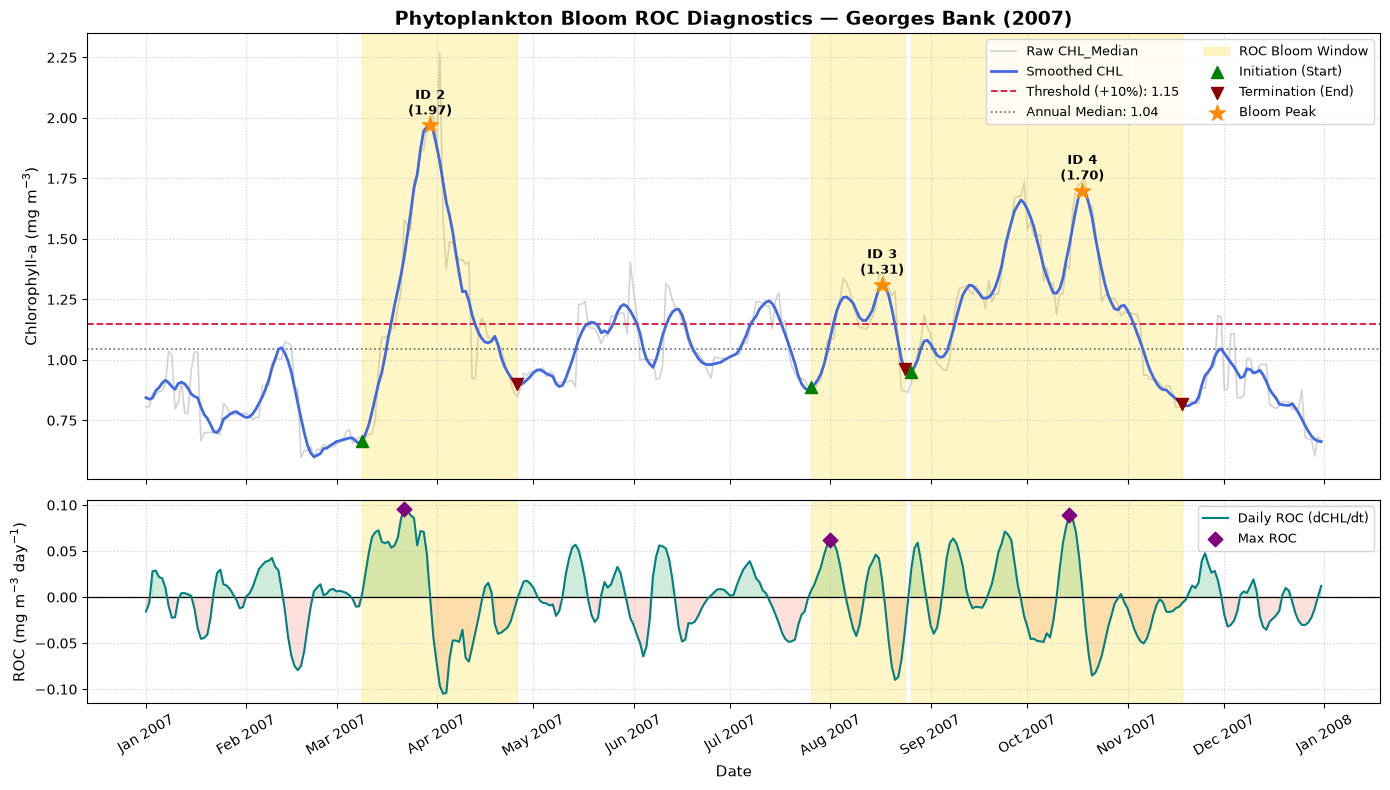

In [18]:
chlfile = get_extracted_files('OCCCI','NES_5REGIONS',prod='CHL',period='D7')
annualfile = get_extracted_files('OCCCI','NES_5REGIONS',prod='CHL',period='ANNUAL')
df, events_df, thlds, out_path = detect_threshold_blooms(chlfile, annualfile, save_output=False, var_name='CHL_Median')
plot_bloom_diagnostics(df, events_df, thlds, subarea='Georges Bank', year=2007, var_name='CHL_Median')

## How the Rate-of-Change (ROC) Logic Works
The ROC method identifies the full biological lifespan of a bloom—from the moment phytoplankton begin growing rapidly (even before crossing the threshold) until growth subsides back to baseline. It runs in five sequential stages:
### 1. Calculate Daily Rate of Change ($\text{ROC} = \frac{d\text{CHL}}{dt}$)
Using the Savitzky-Golay filter with deriv=1, we compute the analytical first derivative of the smoothed CHL curve. Positive ROC means CHL is increasing; negative ROC means it is declining.

### 2. Find Valid Peaks Above Threshold
scipy.signal.find_peaks() locates local maxima separated by at least peak_distance days (default 14) with a minimum prominence (default 0.02). A peak is kept only if it exceeds the climatological threshold (median * (1 + thld)) and sits inside a consecutive above-threshold streak of at least window_for_peak days (default 10).

### 3. Group Nearby Peaks into Single Bloom Events
Consecutive peaks are merged into one multimodal bloom event if they are closer than event_distance days (default 21) or if CHL never drops below the threshold for at least window_for_peak consecutive days between them.

### 4. Determine Initiation & Termination via ROC + Trough Snapping 
* **Initiation candidates:** `init_term_window` (default `5`) consecutive days of sustained growth below threshold ($\text{ROC} \ge 0$ and $\text{CHL} < \text{threshold}$). For each bloom, we take the *last* candidate window before the first peak.

* **Termination candidates:** `init_term_window` consecutive days of sustained decline below threshold ($\text{ROC} < 0$ and $\text{CHL} < \text{threshold}$). For each bloom, we take the *first* candidate window after the last peak (within `search_window = 90` days).

* **Trough snapping:** To anchor the bloom to its true physical baseline, we locate local minima (`CHL` lower than `trough_length = 3` days on both sides, and $\le$ climatological median). If a trough exists in the search window, the start or end date snaps to the trough closest to the ROC candidate.

### 5. Merge Overlapping Events & Flag Threshold Crossings
If two events end up sharing the same start/end bounds or overlap (event[0] <= last_end), they are merged. Finally, we record the exact dates where CHL first crosses above and last drops below the threshold within each bloom.   